<center>
<h1><b> TP3: Prompt Engineering </b>
<h1><b>Classification tasks : Sentiment Analysis </b>
</center>

# Objectives

- Present LLMs as an effective tool to tackle classification problems.
- Illustrate prompt engineering for sentiment analysis.
- Build and evaluate LLMs on broader classification tasks.


# Preparer l'environement

1. Prendre VS Code, je vais créer un un nouveau dossier que je vais appeler **SMA_TokPr** et ouvrir le terminal.
2. **UV** install: utiliser la la commande, pour MacOS: ```curl -LsSf https://astral.sh/uv/install.sh | sh```  sous Windows utiliser la commande dans le powerShell: `powershell -ExecutionPolicy ByPass -c "irm https://astral.sh/uv/install.ps1 | iex"`. Après instalation de UV quittez et relancez VScode.
3. dans le terminal de VsCode utiliser la commande ` uv init ` pour initialiser le projet. Donc ça nous permet de générer la structure des projets notamment avec le fichier **.toml** .
4. créer un environnement virtuel. Avec la commande: ` uv venv ` .
3. autoriser PowerSell à exécuter les scripts avec cette commande dans le terminal: ` Set-ExecutionPolicy -ExecutionPolicy RemoteSigned -Scope Process ` . puis aller au dosssier **Scripts** et activer les scripts avec la commande:  ` .\.venv\Scripts\activate `.
5.  cree un notebook **prompttoken.ipynb** pour le test puis choisir un noyaux(le kernel) et tester avec `print("Bonjour")` .
  

7. installer la bib tiktoken avec ` uv add tiktoken `

In [1]:
import tiktoken

In [2]:
tokenizer=tiktoken.encoding_for_model("gpt-4o")


In [3]:
print(tokenizer.name)


o200k_base


In [4]:
tokenizer=tiktoken.get_encoding("o200k_base")

In [5]:
prompt="Vous êtes un expert en marketing digital. C'est quoi un digital marketer ? "

In [6]:
tokens=tokenizer.encode(prompt)

In [7]:
print(tokens)


[29038, 34077, 537, 8333, 469, 6686, 7058, 13, 363, 6616, 33399, 537, 7058, 95641, 1423, 220]


In [8]:
print(len(tokens))


16


In [9]:
for token in tokens:
    t=tokenizer.decode_single_token_bytes(token).decode("utf-8")
    print(t,end='|')

Vous| êtes| un| expert| en| marketing| digital|.| C|'est| quoi| un| digital| marketer| ?| |

# Utilisation des llm

8. installer les dépendances avec la commande: ` uv add langchain langchain-groq python-dotenv `

In [10]:
from langchain_groq import ChatGroq
from dotenv import load_dotenv

aller dans console.groq.com, générer une api key puis créer un fichier .env qui contient la clé : GROQ_API_KEY=ta_cle_ici

In [11]:
load_dotenv(override=True)

True

In [12]:
llm=ChatGroq(model="openai/gpt-oss-120b", temperature=0)


**apel** a llm

In [13]:
resp=llm.invoke(input=[{"role":"system","content":"Vous êtes un expert en marketing digital"},
{"role":"user","content":"C'est quoi un digital marketer ?"}])

In [14]:
from IPython.display import Markdown, display

In [15]:
display(Markdown(resp.content))

### Qu’est‑ce qu’un **digital marketer** ?

Un **digital marketer** (ou **marketeur digital**) est un professionnel du marketing spécialisé dans la promotion de produits, de services ou de marques **exclusivement ou majoritairement sur les canaux numériques**. Son objectif principal est d’attirer, d’engager et de convertir une audience en ligne grâce à des stratégies data‑driven et à l’utilisation d’outils technologiques.

---

## 1️⃣ Les missions clés d’un digital marketer

| Domaine | Principales activités | Objectif |
|---------|----------------------|----------|
| **Stratégie** | Élaboration d’une feuille de route digitale (cibles, messages, canaux, KPI) | Aligner les actions en ligne avec les objectifs business |
| **Acquisition** | SEO, SEA (Google Ads, Bing Ads), publicités sociales (Facebook, Instagram, LinkedIn, TikTok), display, affiliation | Générer du trafic qualifié et des leads |
| **Contenu** | Création et diffusion de contenus (articles de blog, vidéos, infographies, podcasts, newsletters) | Apporter de la valeur, améliorer le référencement et nourrir la communauté |
| **Social Media** | Gestion des pages, community management, campagnes d’influence | Construire une communauté engagée et renforcer la notoriété |
| **Email & Automation** | Conception de newsletters, scénarios de nurturing, CRM | Fidéliser les prospects et clients, augmenter la valeur à vie (LTV) |
| **Analyse & Optimisation** | Suivi des KPI (trafic, taux de conversion, ROI), A/B testing, reporting | Améliorer continuellement les performances |
| **E‑commerce / Conversion** | Optimisation du tunnel de vente, UX/UI, CRO (Conversion Rate Optimization) | Maximiser les ventes ou les actions souhaitées |
| **Gestion de budget** | Allocation et suivi des dépenses publicitaires, ROI | Garantir la rentabilité des investissements |

---

## 2️⃣ Les compétences indispensables

| Compétence | Pourquoi c’est crucial |
|------------|------------------------|
| **Data & Analytics** (Google Analytics, Data Studio, Tableau) | Décoder le comportement des utilisateurs et mesurer l’impact |
| **SEO & SEA** | Positionner le site dans les moteurs de recherche et capter du trafic payant |
| **Publicité digitale** (Google Ads, Meta Ads, TikTok Ads) | Gérer les campagnes payantes avec un bon ROI |
| **Content Marketing** | Créer du contenu qui attire et retient l’audience |
| **Social Media Management** | Maîtriser les plateformes, les formats et les algorithmes |
| **Email Marketing & Automation** (Mailchimp, HubSpot, Klaviyo) | Nurturer les leads et automatiser les scénarios |
| **UX/UI & CRO** | Optimiser l’expérience utilisateur pour augmenter les conversions |
| **Gestion de projet** | Coordonner les équipes (design, dev, copy, data) et respecter les délais |
| **Veille technologique** | Rester à jour sur les nouvelles tendances (IA, shoppable posts, live streaming) |
| **Soft skills** (communication, créativité, esprit analytique) | Travailler en équipe, convaincre les parties prenantes, innover |

---

## 3️⃣ Les canaux numériques les plus utilisés

| Canal | Exemple d’utilisation |
|-------|-----------------------|
| **Moteurs de recherche** (Google, Bing) | SEO pour le trafic organique, SEA pour les annonces payantes |
| **Réseaux sociaux** (Facebook, Instagram, LinkedIn, TikTok, Pinterest, X) | Posts organiques, stories, publicités ciblées, collaborations influenceurs |
| **Email** | Newsletters, séquences de nurturing, offres exclusives |
| **Sites web & blogs** | Hub de contenu, pages de destination, e‑commerce |
| **Vidéo** (YouTube, Vimeo, TikTok, Reels) | Tutoriels, témoignages, publicités vidéo |
| **Display & Programmatique** | Bannières, retargeting, campagnes cross‑device |
| **Marketplace & plateformes d’achat** (Amazon, Shopify, Etsy) | Gestion de fiches produit, publicités sponsorisées |
| **Chatbots & messagerie** (WhatsApp Business, Messenger, SMS) | Support client, campagnes de conversion instantanée |

---

## 4️⃣ Le parcours type d’un digital marketer

1. **Formation** : Bac +2/3 en marketing, communication, commerce, ou formation spécialisée (Google Digital Garage, HubSpot Academy, certifications Meta, etc.).
2. **Premiers postes** : Assistant(e) marketing digital, community manager, chargé(e) de SEO/SEA.
3. **Spécialisation** : SEO specialist, paid media manager, content strategist, growth hacker.
4. **Responsabilité** : Digital Marketing Manager, Head of Growth, Chief Marketing Officer (CMO) digital.

---

## 5️⃣ Pourquoi le rôle est devenu incontournable ?

- **Consommateur connecté** : Plus de 5 milliards d’internautes dans le monde, la plupart passent la majeure partie de leur temps en ligne.
- **Mesurabilité** : Chaque action digitale peut être tracée, analysée et optimisée.
- **Coût‑efficacité** : Les campagnes ciblées offrent un meilleur ROI que les médias traditionnels.
- **Agilité** : Les stratégies peuvent être ajustées en temps réel selon les performances.
- **Compétitivité** : Les entreprises qui ne maîtrisent pas le digital voient leur part de marché diminuer rapidement.

---

## 🎯 En résumé

Un **digital marketer** est le chef d’orchestre du marketing en ligne : il conçoit, exécute et optimise des stratégies multicanaux basées sur les données pour attirer, convertir et fidéliser les clients dans un environnement numérique en constante évolution. Son succès repose sur une combinaison de compétences techniques (SEO, SEA, analytics, automation) et de qualités créatives/stratégiques, le tout avec une forte orientation résultats.

# ollama llm

# dans power shell installer ollama et utiliser la commande ` ollama run llama3.2:3b `

dans le terminal vscode telecharger ollama ` uv add langchain-ollama `

In [16]:
from langchain_ollama import ChatOllama

In [17]:
llm2 = ChatOllama(model="llama3.2:3b", temperature=0)

In [18]:
resp2=llm2.invoke(input=[{"role":"system","content":"Vous êtes un expert en marketing digital"},{"role":"user","content":"C'est quoi un digital marketer ?"}])

In [19]:
display(Markdown(resp2.content))

Un digital marketer est une personne qui se spécialise dans la création et la mise en œuvre de stratégies de marketing numérique pour aider les entreprises à atteindre leurs objectifs de vente et de réputation en ligne. Les digital marketers travaillent sur divers aspects du marketing numérique, tels que :

1. **SEO (Search Engine Optimization)** : amélioration de la visibilité d'un site web dans les résultats de recherche du moteur de recherche.
2. **Content Marketing** : création et diffusion de contenu de qualité pour attirer et fidéliser une audience cible.
3. **Email Marketing** : création et envoi de campagnes de newsletters et de promotions par courriel.
4. **Social Media Marketing** : gestion des réseaux sociaux et création de contenu pour attirer et fidéliser une audience.
5. **Pay-Per-Click (PPC)** : création et gestion de campagnes publicitaires en ligne, telles que Google AdWords.
6. **Influencer Marketing** : collaboration avec des influenceurs pour promouvoir un produit ou un service.
7. **Analytics et Mesure** : analyse des données pour évaluer l'efficacité des campagnes de marketing numérique.

Les digital marketers doivent avoir une bonne compréhension des tendances du marché, des technologies de marketing numérique et des comportements des consommateurs en ligne. Ils doivent également être capables de créer des stratégies de marketing efficaces, de gérer les budgets et de mesurer les résultats.

En tant qu'expert en marketing digital, je peux vous aider à développer une stratégie de marketing numérique efficace pour votre entreprise !

# Use Case : Sentiment Analysis
## Step 1 : Define Objectives and Metrics

On classe chaque avis en **positive** ou **negative**. Métriques : accuracy et **micro-F1** (`f1_score` de scikit-learn, `average="micro"`).

Installer les bibliothèques : ` uv add pandas scikit-learn tqdm matplotlib `

## Step 2 : Assemble Data

Le prof fournit le dataset IMDB en CSV (`dataset_imdb/IMDB Dataset.csv`, colonnes `review` et `sentiment`). On le lit avec pandas à la place de `load_dataset("imdb")`. Placer le dossier `dataset_imdb` à côté du notebook.

In [20]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

In [21]:
train_df = pd.read_csv("dataset_imdb/IMDB Dataset.csv").rename(columns={"review": "text"})
train_df["text"] = train_df["text"].str.replace("<br />", " ", regex=False)

# Avis courts seulement (limite de tokens de Groq), classes équilibrées
train_df = train_df[train_df["text"].str.len() < 500]
train_df = train_df.groupby("sentiment").sample(2300, random_state=42).reset_index(drop=True)
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   text       4600 non-null   str  
 1   sentiment  4600 non-null   str  
dtypes: str(2)
memory usage: 72.0 KB


In [22]:
train_df.sentiment.value_counts()

sentiment
negative    2300
positive    2300
Name: count, dtype: int64

In [23]:
train_df.sample(6)

,text,sentiment
3088,There's something wonderful about the fact tha...,positive
4581,this moving was intriguing and absorbing; howe...,positive
2127,I watched part of the first part of this movie...,negative
2943,"This movie is pretty good as it is, but the un...",positive
2435,What a fun movie experience! I was expecting a...,positive
2683,This is my favorite movie of all time. I just ...,positive


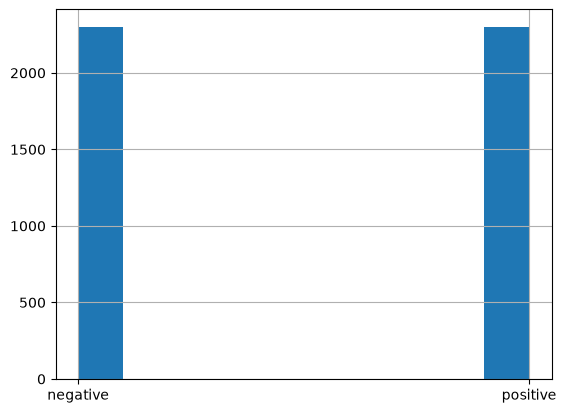

In [24]:
train_df.sentiment.hist()
plt.show()

Séparation en deux : 80 % pour les exemples *few-shot*, 20 % pour les *gold examples*.

In [25]:
examples_df, gold_examples_df = train_test_split(train_df, test_size=0.2, random_state=42)
(examples_df.shape, gold_examples_df.shape)

((3680, 2), (920, 2))

In [26]:
columns = ['text', 'sentiment']
gold_examples = (
    gold_examples_df.loc[:, columns]
    .sample(20, random_state=42)
    .to_json(orient='records'))
json.loads(gold_examples)[0]

{'text': 'A poor basketball movie. A gruff coach with a dubious background comes to a small Indiana high school basketball team in the 1950\'s and coaches the boys to victory by "breaking them down first, and then building them up."  Not a bad subject. Photography OK. But the plot is totally predictable. No real sub-plots. Nothing added to make the movie exciting. You know what is going to happen from the very beginning. Suitable for 4th Graders.',
 'sentiment': 'negative'}

## Étape 3 : Élaborer le prompt
### Prompt 1 : Zero-shot

In [27]:
user_message_template = """```{movie_review}```"""

zero_shot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.
"""
zero_shot_prompt = [{'role': 'system', 'content': zero_shot_system_message}]

### Prompt 2 : Few-shot

In [28]:
few_shot_system_message = zero_shot_system_message

def create_examples(dataset, n=4):
    positive_reviews = (dataset.sentiment == 'positive')
    negative_reviews = (dataset.sentiment == 'negative')
    columns_to_select = ['text', 'sentiment']
    positive_examples = dataset.loc[positive_reviews, columns_to_select].sample(n)
    negative_examples = dataset.loc[negative_reviews, columns_to_select].sample(n)
    examples = pd.concat([positive_examples, negative_examples])
    # sampling without replacement is equivalent to random shuffling
    randomized_examples = examples.sample(2*n, replace=False)
    return randomized_examples.to_json(orient='records')

In [29]:
examples = create_examples(examples_df, 2)
json.loads(examples)

[{'text': 'I was impressed that I could take my 5 year old son to this movie without having to cover his ears or eyes. No sex scenes, no profanity, and not even any violence. Just good entertainment, enjoyable from beginning to end. Dennis Quaid pulls off this movie very well.',
  'sentiment': 'positive'},
 {'text': "When the Grinch came out I was excited though I thought it was going to be a happy go lucky film and it was. Though it did have a little Nightmare before Christmas touch to it. You know kind of dark and spooky. I loved this film because it helped fill people with the Christmas spirit. So mostly the Grinch saved Christmas. And what happened then well in Whoville they say that the Grinch's small heart grew three sizes that day. MERRY GRINCHMAS!",
  'sentiment': 'positive'},
 {'text': "One of Frances Farmer's earliest movies; at 22, she is absolutely beautiful. Bing Crosby is in great voice, but the songs are not his best. Martha Raye and Bob Burns are interesting, but their 

In [30]:
def create_prompt(system_message, examples, user_message_template):
    few_shot_prompt = [{'role': 'system', 'content': system_message}]
    for example in json.loads(examples):
        example_review = example['text']
        example_sentiment = example['sentiment']
        few_shot_prompt.append({
            'role': 'user',
            'content': user_message_template.format(movie_review=example_review)})
        few_shot_prompt.append({
            'role': 'assistant',
            'content': f"{example_sentiment}"})
    return few_shot_prompt

In [31]:
few_shot_prompt = create_prompt(few_shot_system_message, examples, user_message_template)
few_shot_prompt

[{'role': 'system',
  'content': "\nClassify the sentiment of movie reviews presented in the input as 'positive' or 'negative'\nMovie reviews will be delimited by triple backticks in the input.\nAnswer only 'positive' or 'negative'\nDo not explain your answer.\n"},
 {'role': 'user',
  'content': '```I was impressed that I could take my 5 year old son to this movie without having to cover his ears or eyes. No sex scenes, no profanity, and not even any violence. Just good entertainment, enjoyable from beginning to end. Dennis Quaid pulls off this movie very well.```'},
 {'role': 'assistant', 'content': 'positive'},
 {'role': 'user',
  'content': "```When the Grinch came out I was excited though I thought it was going to be a happy go lucky film and it was. Though it did have a little Nightmare before Christmas touch to it. You know kind of dark and spooky. I loved this film because it helped fill people with the Christmas spirit. So mostly the Grinch saved Christmas. And what happened th

### Prompt 3 : Chain-of-Thought

In [32]:
cot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks ``` in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.

Instructions:
1. Carefully read the text of the review and think through the options for sentiment provided
2. Consider the overall sentiment of the review and estimate the probability of the review being positive

To reiterate, your answer should strictly only contain the label: positive or negative
"""

cot_few_shot_prompt = create_prompt(cot_system_message, examples, user_message_template)

## Step 4 : Evaluate Prompts

On utilise le modèle Groq `llm` défini plus haut. Une pause (`sleep`) entre les appels évite de dépasser les limites de débit de Groq.

In [33]:
def evaluate_prompt(prompt, gold_examples, user_message_template, model, sleep=2):
    model_predictions, ground_truths = [], []
    for example in json.loads(gold_examples):
        gold_input = example['text']
        user_input = [{
            'role': 'user',
            'content': user_message_template.format(movie_review=gold_input)}]
        try:
            response = model.invoke(prompt + user_input)
            response_content = response.content if hasattr(response, 'content') else response
            if 'negative' in response_content.strip().lower():
                prediction = 'negative'
            elif 'positive' in response_content.strip().lower():
                prediction = 'positive'
            else:
                prediction = 'unknown'
            model_predictions.append(prediction)
            ground_truths.append(example['sentiment'])
        except Exception as e:
            print(e)
            time.sleep(10)
            continue
        time.sleep(sleep)
    micro_f1_score = f1_score(ground_truths, model_predictions, average="micro")
    return micro_f1_score

In [34]:
evaluate_prompt(zero_shot_prompt, gold_examples, user_message_template, llm)

1.0

In [35]:
evaluate_prompt(few_shot_prompt, gold_examples, user_message_template, llm)

1.0

In [36]:
evaluate_prompt(cot_few_shot_prompt, gold_examples, user_message_template, llm)

1.0

Évaluation répétée avec plusieurs tirages d'exemples (3 runs pour rester dans les limites de Groq ; augmenter si possible).

In [37]:
num_eval_runs = 3
few_shot_performance, cot_few_shot_performance = [], []
for _ in tqdm(range(num_eval_runs)):
    # Nouveau tirage d'exemples à chaque run
    examples = create_examples(examples_df)
    few_shot_prompt = create_prompt(few_shot_system_message, examples, user_message_template)
    cot_few_shot_prompt = create_prompt(cot_system_message, examples, user_message_template)
    few_shot_performance.append(
        evaluate_prompt(few_shot_prompt, gold_examples, user_message_template, llm))
    cot_few_shot_performance.append(
        evaluate_prompt(cot_few_shot_prompt, gold_examples, user_message_template, llm))

100%|██████████| 3/3 [11:16<00:00, 225.51s/it]


In [38]:
for name, perf in [("few-shot", few_shot_performance), ("CoT", cot_few_shot_performance)]:
    print(f"{name} : f1_score Moyen = {np.mean(perf):.3f}, Standard Deviation = {np.std(perf):.3f}")

few-shot : f1_score Moyen = 1.000, Standard Deviation = 0.000
CoT : f1_score Moyen = 1.000, Standard Deviation = 0.000
